# 20231017_HippAu_118
# 20231017_HippAu_132
# 20231026_HippAu_14
# 20240111_AMmilled4-1_119
# 20240111_WaffleHipp_227

# 20240901_AMmilled13-1_20

In [20]:
import starfile
from findingampa.utils.analysis import render_active_zonograms, calculate_probit, estimate_anisotropic_gaussian_for_probit, calculate_1q_p_value, render_active_zonograms, select_aunps
import pymeshlab
from pathlib import Path
from scipy.spatial import cKDTree
from matplotlib import pyplot as plt
import torch
import mrcfile
import numpy as np

In [127]:
tom = "20240111_WaffleHipp_227"
aunp_data = starfile.read(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/{tom}/best_alignment/aunps/aunp_tm_BP.star")

In [214]:
amp_rank, amp_pro = calculate_probit(aunp_data["faTomo_gaussianFitAmplitude"].to_numpy()* -1)
pea_rank, pea_pro = calculate_probit(aunp_data["faTM_PeakScore"].to_numpy())

Dinv_, Uinv__ = estimate_anisotropic_gaussian_for_probit(amp_pro, pea_pro, None, False, False)
pval,neg_log_p1q_equ_pro_ = calculate_1q_p_value(amp_pro, pea_pro, Dinv_, Uinv__)

sel_aunps = aunp_data[aunp_data["faTomo_gaussianFitAmplitude"] < -6]
sel_aunps = sel_aunps[sel_aunps["faTomo_gaussianFitSigmaX"] < 1]
sel_aunps = sel_aunps[sel_aunps["faTM_PeakScore"] > 0.35]

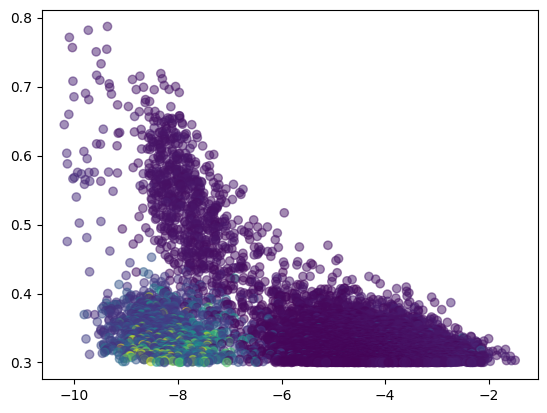

In [206]:
# Use interactive Backend
plt.close('all')
plt.switch_backend('agg')
%matplotlib inline
# Reseset plt
plt.clf()
plt.scatter(aunp_data["faTomo_gaussianFitAmplitude"].to_numpy(), aunp_data["faTM_PeakScore"].to_numpy(),c=aunp_data["faTomo_gaussianFitSigmaX"].to_numpy(), alpha=0.5)


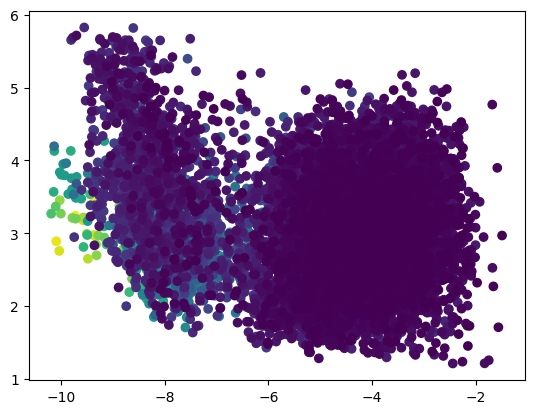

In [207]:
plt.scatter(aunp_data["faTomo_gaussianFitAmplitude"].to_numpy(), aunp_data["faTM_gaussianFitSigmaX"].to_numpy(), c=aunp_data["faTM_PeakScore"].to_numpy())

In [208]:
with mrcfile.open(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/{tom}/best_alignment/active_zonograms/active_zonogram_0.mrc", permissive=True) as mrc:
    res_ddw = torch.tensor(mrc.data.copy())

In [209]:
az_data = np.load(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/{tom}/best_alignment/active_zonograms/active_zonogram_0.npy" ,allow_pickle=True)

In [210]:
az_data

array({'cs': array([[ 0.80465534,  0.59374219, -0.        ],
       [ 0.10726699, -0.14537111, -0.98354514],
       [-0.58397224,  0.79141485, -0.18066258]]), 'center': array([394.93770863, 379.38355426, 190.28713871]), 'objects': (0, 0)},
      dtype=object)

In [215]:
fig = render_active_zonograms((None,None,res_ddw))
selected_aunp_pos = sel_aunps[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values + sel_aunps[["faTomo_gaussianFitX", "faTomo_gaussianFitY", "faTomo_gaussianFitZ"]].values

selected_aunp_pos_transformed = (selected_aunp_pos - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
selected_aunp_pos_transformed += np.floor(np.array(res_ddw.shape)[[2,1,0]]/2)
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(res_ddw.shape)[[2,1,0]], axis=1)]
(axxy, axxz, axyz) = fig.get_axes()
axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], s=1,c='r')
axxz.scatter(selected_aunp_pos_transformed[:,2], selected_aunp_pos_transformed[:,1], s=1,c='r')
axyz.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,2], s=1,c='r')


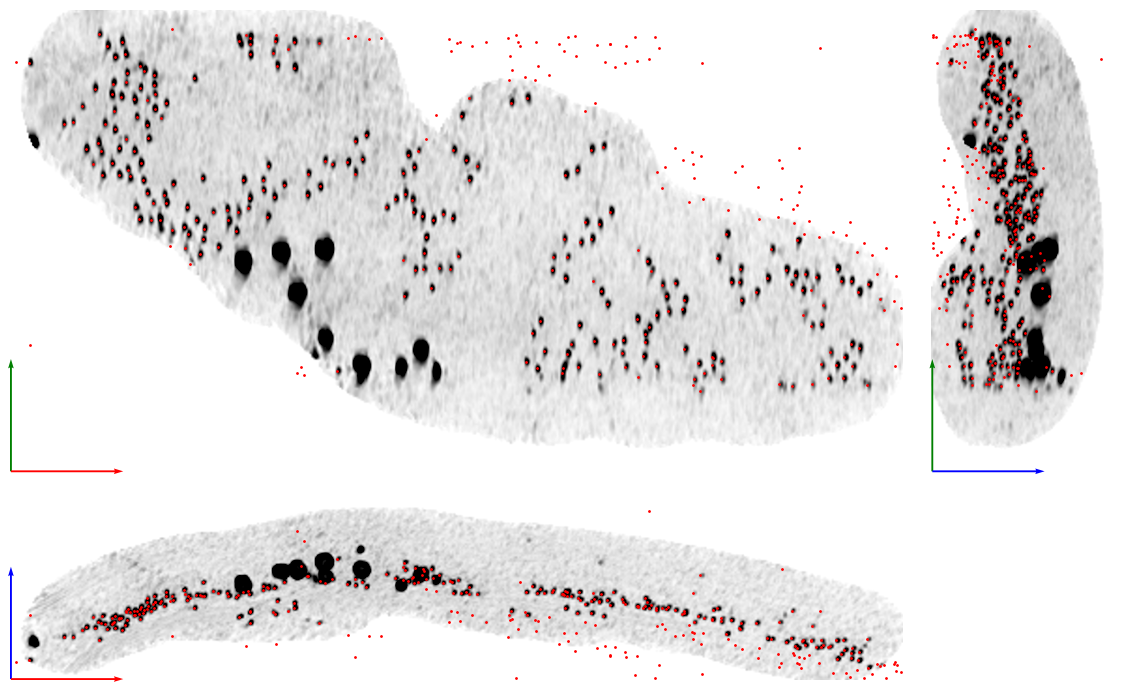

In [216]:
fig

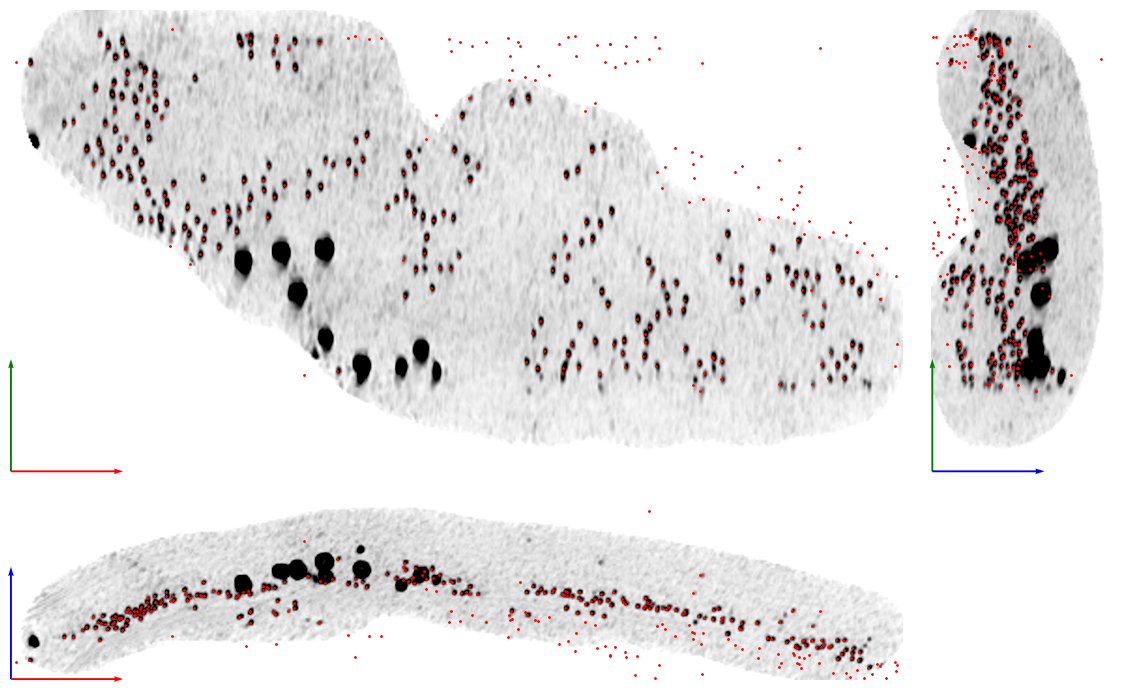

In [213]:
fig